<a href="https://colab.research.google.com/github/aadvikchaturvedi/Tennis_Prediction_Model/blob/main/tennis_prediction_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split


In [93]:
df = pd.read_csv('/content/data/atp_matches_2024.csv')
for i in range(2023, 1967, -1):
  temp = pd.read_csv('/content/data/atp_matches_' + str(i) + '.csv')
  df = pd.concat([df, temp], axis = 0)

In [94]:
df.shape

(194996, 49)

In [95]:
df.isnull().sum()
toDrop = ['winner_id', 'loser_id', 'winner_age', 'loser_age',
          'w_ace', 'w_df', 'w_svpt', 'w_1stIn', 'w_1stWon',
          'w_2ndWon','w_SvGms', 'w_bpSaved', 'w_bpFaced',
          'l_ace', 'l_df', 'l_svpt','l_1stIn', 'l_1stWon',
          'l_2ndWon', 'l_SvGms','l_bpSaved', 'l_bpFaced','winner_rank',
          'winner_rank_points','loser_rank', 'loser_rank_points', 'loser_ht', 'winner_ht']
df_filtered = df.dropna(subset=toDrop)
df_filtered = df_filtered.reset_index(drop=True)
df_filtered

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,...,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
0,2024-0339,Brisbane,Hard,32.0,A,20240101,300,105777,2.0,NaN,...,58.0,44.0,16.0,11.0,8.0,9.0,14.0,2570.0,8.0,3660.0
1,2024-0339,Brisbane,Hard,32.0,A,20240101,299,208029,1.0,NaN,...,35.0,31.0,10.0,11.0,5.0,7.0,8.0,3660.0,39.0,1122.0
2,2024-0339,Brisbane,Hard,32.0,A,20240101,298,105777,2.0,NaN,...,39.0,24.0,14.0,10.0,5.0,7.0,14.0,2570.0,55.0,902.0
3,2024-0339,Brisbane,Hard,32.0,A,20240101,297,208029,1.0,NaN,...,51.0,31.0,16.0,10.0,3.0,5.0,8.0,3660.0,116.0,573.0
4,2024-0339,Brisbane,Hard,32.0,A,20240101,296,126128,NaN,NaN,...,37.0,27.0,16.0,10.0,5.0,8.0,39.0,1122.0,44.0,1021.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95370,1991-605,Tour Finals,Carpet,8.0,F,19911112,11,101948,NaN,NaN,...,48.0,31.0,21.0,12.0,4.0,6.0,7.0,2122.0,8.0,1749.0
95371,1991-605,Tour Finals,Carpet,8.0,F,19911112,12,101736,NaN,NaN,...,39.0,30.0,8.0,10.0,6.0,8.0,8.0,1749.0,4.0,2675.0
95372,1991-605,Tour Finals,Carpet,8.0,F,19911112,13,101414,NaN,NaN,...,35.0,26.0,21.0,11.0,4.0,6.0,3.0,2852.0,4.0,2675.0
95373,1991-605,Tour Finals,Carpet,8.0,F,19911112,14,101414,NaN,NaN,...,58.0,42.0,16.0,14.0,6.0,9.0,3.0,2852.0,7.0,2122.0


In [96]:
final_data = pd.DataFrame()
final_data['WINNER_ID'] = df_filtered['winner_id']
final_data['LOSER_ID'] = df_filtered['loser_id']
final_data['POINT_DIFF'] = df_filtered['winner_rank_points']-df_filtered['loser_rank_points']
final_data['RANK_DIFF'] = df_filtered['winner_rank']-df_filtered['loser_rank']
final_data['HT_DIFF'] = df_filtered['winner_ht']-df_filtered['loser_ht']
final_data['BEST_OF'] = df_filtered['best_of']
final_data['DRAW_SIZE'] = df_filtered['draw_size']
final_data['AGE_DIFF'] = df_filtered['winner_age'] - df_filtered['loser_age']
final_data

,WINNER_ID,LOSER_ID,POINT_DIFF,RANK_DIFF,HT_DIFF,BEST_OF,DRAW_SIZE,AGE_DIFF
0,105777,208029,-1090.0,6.0,3.0,3,32.0,12.0
1,208029,126128,2538.0,-31.0,3.0,3,32.0,-5.8
2,105777,111442,1668.0,-41.0,8.0,3,32.0,2.9
3,208029,105902,3087.0,-108.0,5.0,3,32.0,-11.3
4,126128,208286,101.0,-5.0,0.0,3,32.0,3.6
...,...,...,...,...,...,...,...,...
95370,101948,101736,373.0,-1.0,5.0,3,8.0,-1.3
95371,101736,101529,-926.0,4.0,-13.0,3,8.0,-1.5
95372,101414,101529,177.0,-1.0,-3.0,3,8.0,0.9
95373,101414,101948,730.0,-4.0,5.0,3,8.0,3.7


In [97]:
# Ace / double fault differences
final_data['ACE_DIFF'] = df_filtered['w_ace'] - df_filtered['l_ace']
final_data['DF_DIFF'] = df_filtered['w_df'] - df_filtered['l_df']

# First serve in % (add epsilon to avoid divide by zero)
eps = 1e-6
final_data['W_1ST_PCT'] = df_filtered['w_1stIn'] / (df_filtered['w_svpt'] + eps)
final_data['L_1st_PCT'] = df_filtered['l_1stIn'] / (df_filtered['l_svpt'] + eps)
final_data['FIRST_SERVE_PCT_DIFF'] = final_data['W_1ST_PCT'] - final_data['L_1st_PCT']

# First serve win %
final_data['W_1ST_WIN_PCT'] = df_filtered['w_1stWon'] / (df_filtered['w_1stIn'] + eps)
final_data['L_1ST_WIN_PCT'] = df_filtered['l_1stWon'] / (df_filtered['l_1stIn'] + eps)
final_data['FIRST_SERVE_WIN_DIFF'] = final_data['W_1ST_WIN_PCT'] - final_data['L_1ST_WIN_PCT']

# Second serve win %
final_data['W_2ND_WIN_PCT'] = df_filtered['w_2ndWon'] / (df_filtered['w_svpt'] - df_filtered['w_1stIn'] + eps)
final_data['L_2ND_WIN_PCT'] = df_filtered['l_2ndWon'] / (df_filtered['l_svpt'] - df_filtered['l_1stIn'] + eps)
final_data['SECOND_SERVE_WIN_DIFF'] = final_data['W_2ND_WIN_PCT'] - final_data['L_2ND_WIN_PCT']

# Break point save %
final_data['W_BP_SAVE_PCT'] = df_filtered['w_bpSaved'] / (df_filtered['w_bpFaced'] + eps)
final_data['L_BP_SAVE_PCT'] = df_filtered['l_bpSaved'] / (df_filtered['l_bpFaced'] + eps)
final_data['BP_SAVE_PCT_DIFF'] = final_data['W_BP_SAVE_PCT'] - final_data['L_BP_SAVE_PCT']
# grand slam or not

final_data

,WINNER_ID,LOSER_ID,POINT_DIFF,RANK_DIFF,HT_DIFF,BEST_OF,DRAW_SIZE,AGE_DIFF,ACE_DIFF,DF_DIFF,...,FIRST_SERVE_PCT_DIFF,W_1ST_WIN_PCT,L_1ST_WIN_PCT,FIRST_SERVE_WIN_DIFF,W_2ND_WIN_PCT,L_2ND_WIN_PCT,SECOND_SERVE_WIN_DIFF,W_BP_SAVE_PCT,L_BP_SAVE_PCT,BP_SAVE_PCT_DIFF
0,105777,208029,-1090.0,6.0,3.0,3,32.0,12.0,-1.0,-1.0,...,0.092176,0.769231,0.758621,0.010610,0.590909,0.432432,0.158477,1.000000,0.888889,0.111111
1,208029,126128,2538.0,-31.0,3.0,3,32.0,-5.8,2.0,-1.0,...,0.136364,0.812500,0.885714,-0.073214,0.458333,0.322581,0.135753,0.500000,0.714286,-0.214286
2,105777,111442,1668.0,-41.0,8.0,3,32.0,2.9,5.0,2.0,...,0.042610,0.866667,0.615385,0.251282,0.454545,0.608696,-0.154150,1.000000,0.714286,0.285714
3,208029,105902,3087.0,-108.0,5.0,3,32.0,-11.3,8.0,-2.0,...,-0.108492,0.861111,0.607843,0.253268,0.586207,0.615385,-0.029178,0.999999,0.600000,0.399999
4,126128,208286,101.0,-5.0,0.0,3,32.0,3.6,6.0,1.0,...,0.052809,0.837209,0.729730,0.107480,0.466667,0.500000,-0.033333,0.666666,0.625000,0.041667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95370,101948,101736,373.0,-1.0,5.0,3,8.0,-1.3,11.0,1.0,...,0.055660,0.780000,0.645833,0.134167,0.500000,0.617647,-0.117647,0.666667,0.666667,0.000000
95371,101736,101529,-926.0,4.0,-13.0,3,8.0,-1.5,-14.0,-2.0,...,0.005650,0.782609,0.769231,0.013378,0.565217,0.400000,0.165217,1.000000,0.750000,0.250000
95372,101414,101529,177.0,-1.0,-3.0,3,8.0,0.9,5.0,-5.0,...,0.336996,0.886364,0.742857,0.143506,0.500000,0.488372,0.011628,0.000000,0.666667,-0.666667
95373,101414,101948,730.0,-4.0,5.0,3,8.0,3.7,13.0,-1.0,...,-0.010438,0.851064,0.724138,0.126926,0.636364,0.410256,0.226107,0.000000,0.666667,-0.666667


In [98]:
from collections import defaultdict
from tqdm import tqdm

# Storage dictionaries for H2H tracking
total_h2h_dict = defaultdict(int)  # (winner, loser) pair total wins
total_h2h_surface_dict = defaultdict(lambda: defaultdict(int))  # surface -> (winner, loser) -> wins

# Feature lists to populate
h2h_features = []
h2h_surface_features = []

# Iterate through match records
for winner_id, loser_id, surface in tqdm(zip(df_filtered['winner_id'], df_filtered['loser_id'], df_filtered['surface']), total=len(df_filtered)):
    # Get historical H2H before this match
    h2h_w = total_h2h_dict[(winner_id, loser_id)]
    h2h_l = total_h2h_dict[(loser_id, winner_id)]
    h2h_diff = h2h_w - h2h_l

    # Get historical surface-specific H2H before this match
    surf_h2h_w = total_h2h_surface_dict[surface][(winner_id, loser_id)]
    surf_h2h_l = total_h2h_surface_dict[surface][(loser_id, winner_id)]
    surf_h2h_diff = surf_h2h_w - surf_h2h_l

    # Store current match features
    h2h_features.append(h2h_diff)
    h2h_surface_features.append(surf_h2h_diff)

    # Update counts after the match
    total_h2h_dict[(winner_id, loser_id)] += 1
    total_h2h_surface_dict[surface][(winner_id, loser_id)] += 1
final_data['H2H_WIN'] = h2h_features
final_data['H2H_WIN_SURFACE'] = h2h_surface_features


100%|██████████| 95375/95375 [00:00<00:00, 155466.48it/s]


In [99]:
final_data

,WINNER_ID,LOSER_ID,POINT_DIFF,RANK_DIFF,HT_DIFF,BEST_OF,DRAW_SIZE,AGE_DIFF,ACE_DIFF,DF_DIFF,...,L_1ST_WIN_PCT,FIRST_SERVE_WIN_DIFF,W_2ND_WIN_PCT,L_2ND_WIN_PCT,SECOND_SERVE_WIN_DIFF,W_BP_SAVE_PCT,L_BP_SAVE_PCT,BP_SAVE_PCT_DIFF,H2H_WIN,H2H_WIN_SURFACE
0,105777,208029,-1090.0,6.0,3.0,3,32.0,12.0,-1.0,-1.0,...,0.758621,0.010610,0.590909,0.432432,0.158477,1.000000,0.888889,0.111111,0,0
1,208029,126128,2538.0,-31.0,3.0,3,32.0,-5.8,2.0,-1.0,...,0.885714,-0.073214,0.458333,0.322581,0.135753,0.500000,0.714286,-0.214286,0,0
2,105777,111442,1668.0,-41.0,8.0,3,32.0,2.9,5.0,2.0,...,0.615385,0.251282,0.454545,0.608696,-0.154150,1.000000,0.714286,0.285714,0,0
3,208029,105902,3087.0,-108.0,5.0,3,32.0,-11.3,8.0,-2.0,...,0.607843,0.253268,0.586207,0.615385,-0.029178,0.999999,0.600000,0.399999,0,0
4,126128,208286,101.0,-5.0,0.0,3,32.0,3.6,6.0,1.0,...,0.729730,0.107480,0.466667,0.500000,-0.033333,0.666666,0.625000,0.041667,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95370,101948,101736,373.0,-1.0,5.0,3,8.0,-1.3,11.0,1.0,...,0.645833,0.134167,0.500000,0.617647,-0.117647,0.666667,0.666667,0.000000,5,2
95371,101736,101529,-926.0,4.0,-13.0,3,8.0,-1.5,-14.0,-2.0,...,0.769231,0.013378,0.565217,0.400000,0.165217,1.000000,0.750000,0.250000,3,1
95372,101414,101529,177.0,-1.0,-3.0,3,8.0,0.9,5.0,-5.0,...,0.742857,0.143506,0.500000,0.488372,0.011628,0.000000,0.666667,-0.666667,2,3
95373,101414,101948,730.0,-4.0,5.0,3,8.0,3.7,13.0,-1.0,...,0.724138,0.126926,0.636364,0.410256,0.226107,0.000000,0.666667,-0.666667,-7,-1


In [100]:
# # Add a placeholder 'RESULT' column (you may want to define this based on your task)
final_data['RESULT'] = 1

# sns.pairplot(final_data.iloc[:2000, :], hue='RESULT')

In [101]:
final_data.columns

Index(['WINNER_ID', 'LOSER_ID', 'POINT_DIFF', 'RANK_DIFF', 'HT_DIFF',
       'BEST_OF', 'DRAW_SIZE', 'AGE_DIFF', 'ACE_DIFF', 'DF_DIFF', 'W_1ST_PCT',
       'L_1st_PCT', 'FIRST_SERVE_PCT_DIFF', 'W_1ST_WIN_PCT', 'L_1ST_WIN_PCT',
       'FIRST_SERVE_WIN_DIFF', 'W_2ND_WIN_PCT', 'L_2ND_WIN_PCT',
       'SECOND_SERVE_WIN_DIFF', 'W_BP_SAVE_PCT', 'L_BP_SAVE_PCT',
       'BP_SAVE_PCT_DIFF', 'H2H_WIN', 'H2H_WIN_SURFACE', 'RESULT'],
      dtype='object')

In [102]:
import pandas as pd

# Step 1: Player 1 is WINNER
p1_df = final_data.copy()
p1_df['PLAYER_1_ID'] = final_data['WINNER_ID']
p1_df['PLAYER_2_ID'] = final_data['LOSER_ID']
p1_df['TARGET'] = 1

# Step 2: Player 1 is LOSER
p2_df = final_data.copy()
p2_df['PLAYER_1_ID'] = final_data['LOSER_ID']
p2_df['PLAYER_2_ID'] = final_data['WINNER_ID']
p2_df['TARGET'] = 0

# Step 3: Flip diff-based features
diff_cols = [
    'POINT_DIFF', 'RANK_DIFF', 'HT_DIFF', 'ACE_DIFF', 'DF_DIFF',
    'FIRST_SERVE_PCT_DIFF', 'FIRST_SERVE_WIN_DIFF',
    'SECOND_SERVE_WIN_DIFF', 'BP_SAVE_PCT_DIFF',
    'H2H_WIN', 'H2H_WIN_SURFACE'
]

for col in diff_cols:
    p2_df[col] = -p2_df[col]
final_symmetric_data = pd.concat([p1_df, p2_df], ignore_index=True)
final_symmetric_data.drop(columns=['WINNER_ID', 'LOSER_ID', 'RESULT'], inplace=True)


In [103]:
final_symmetric_data

,POINT_DIFF,RANK_DIFF,HT_DIFF,BEST_OF,DRAW_SIZE,AGE_DIFF,ACE_DIFF,DF_DIFF,W_1ST_PCT,L_1st_PCT,...,L_2ND_WIN_PCT,SECOND_SERVE_WIN_DIFF,W_BP_SAVE_PCT,L_BP_SAVE_PCT,BP_SAVE_PCT_DIFF,H2H_WIN,H2H_WIN_SURFACE,PLAYER_1_ID,PLAYER_2_ID,TARGET
0,-1090.0,6.0,3.0,3,32.0,12.0,-1.0,-1.0,0.702703,0.610526,...,0.432432,0.158477,1.000000,0.888889,0.111111,0,0,105777,208029,1
1,2538.0,-31.0,3.0,3,32.0,-5.8,2.0,-1.0,0.666667,0.530303,...,0.322581,0.135753,0.500000,0.714286,-0.214286,0,0,208029,126128,1
2,1668.0,-41.0,8.0,3,32.0,2.9,5.0,2.0,0.671642,0.629032,...,0.608696,-0.154150,1.000000,0.714286,0.285714,0,0,105777,111442,1
3,3087.0,-108.0,5.0,3,32.0,-11.3,8.0,-2.0,0.553846,0.662338,...,0.615385,-0.029178,0.999999,0.600000,0.399999,0,0,208029,105902,1
4,101.0,-5.0,0.0,3,32.0,3.6,6.0,1.0,0.589041,0.536232,...,0.500000,-0.033333,0.666666,0.625000,0.041667,0,0,126128,208286,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190745,-373.0,1.0,-5.0,3,8.0,-1.3,-11.0,-1.0,0.641026,0.585366,...,0.617647,0.117647,0.666667,0.666667,-0.000000,-5,-2,101736,101948,0
190746,926.0,-4.0,13.0,3,8.0,-1.5,14.0,2.0,0.666667,0.661017,...,0.400000,-0.165217,1.000000,0.750000,-0.250000,-3,-1,101529,101736,0
190747,-177.0,1.0,3.0,3,8.0,0.9,-5.0,5.0,0.785714,0.448718,...,0.488372,-0.011628,0.000000,0.666667,0.666667,-2,-3,101529,101414,0
190748,-730.0,4.0,-5.0,3,8.0,3.7,-13.0,1.0,0.587500,0.597938,...,0.410256,-0.226107,0.000000,0.666667,0.666667,7,1,101948,101414,0


In [105]:
keep_cols = ['ACE_DIFF', 'DF_DIFF', 'FIRST_SERVE_PCT_DIFF',
             'FIRST_SERVE_WIN_DIFF', 'SECOND_SERVE_WIN_DIFF',
             'BP_SAVE_PCT_DIFF', 'RANK_DIFF', 'AGE_DIFF',
             'HT_DIFF', 'H2H_WIN', 'H2H_WIN_SURFACE']  # Add your own

X = final_symmetric_data[keep_cols]
y = final_symmetric_data['TARGET']

# Split into training and testing sets
x_train, x_test_temp, y_train, y_test_temp = train_test_split(X, y, test_size=0.4, random_state=42)

# Split the temporary test set into test and cross-validation sets
x_test, x_cv, y_test, y_cv = train_test_split(x_test_temp, y_test_temp, test_size=0.5, random_state=42)


model = XGBClassifier()
model.fit(x_train, y_train)

predict_train = model.predict(x_train)
predict_test = model.predict(x_test)
predict_cv = model.predict(x_cv)

In [108]:
 from sklearn.metrics import accuracy_score
 print(f"Train Accuracy: {accuracy_score(predict_train, y_train)*100}")
 print(f"Test Accuracy: {accuracy_score(predict_test, y_test)*100}")
 print(f"Cross-Validation: {accuracy_score(predict_cv, y_cv)*100}")

Train Accuracy: 94.90694626474443
Test Accuracy: 92.90694626474443
Cross-Validation: 92.92791612057667


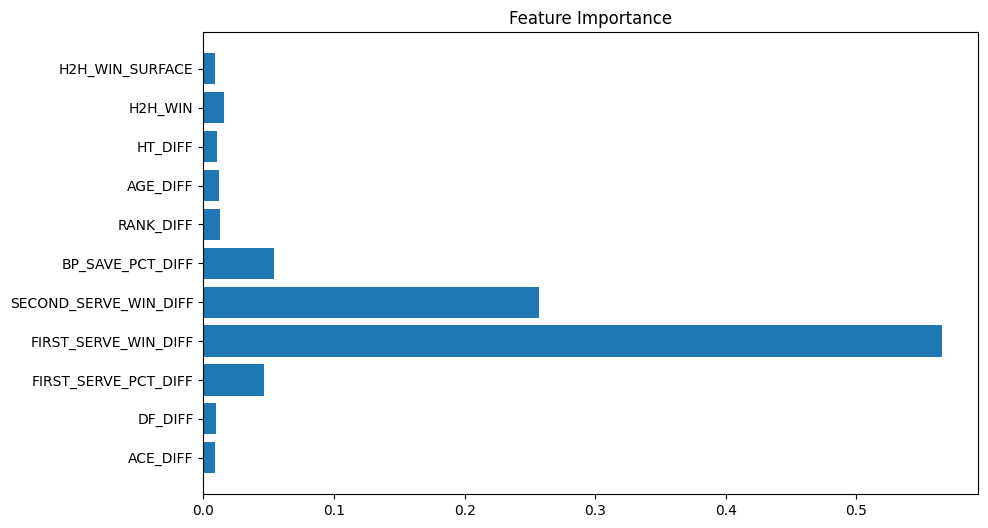

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
importance = model.feature_importances_
features = X.columns
plt.barh(features, importance)
plt.title("Feature Importance")
plt.show()

In [114]:
!pip list > requirement.txt

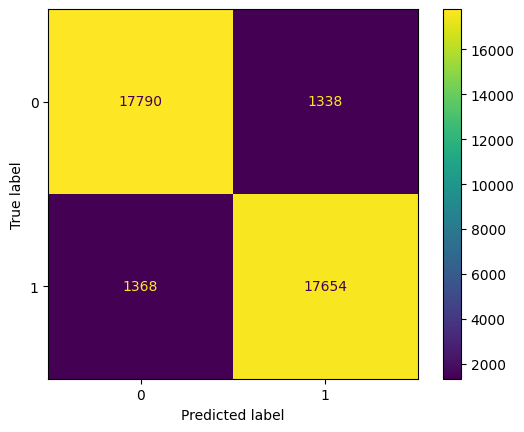

In [116]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predict_test)
disp = ConfusionMatrixDisplay(cm)
disp.plot()

In [119]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predict_test))


              precision    recall  f1-score   support

           0       0.93      0.93      0.93     19128
           1       0.93      0.93      0.93     19022

    accuracy                           0.93     38150
   macro avg       0.93      0.93      0.93     38150
weighted avg       0.93      0.93      0.93     38150



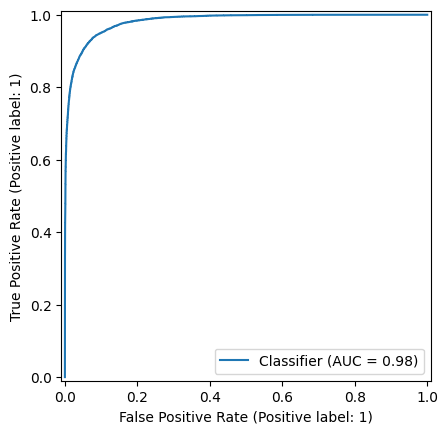

ROC AUC Score: 0.9823


In [121]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_probs = model.predict_proba(x_test)[:, 1]
RocCurveDisplay.from_predictions(y_test, y_probs)
plt.show()

print(f"ROC AUC Score: {roc_auc_score(y_test, y_probs):.4f}")